# Choose an area. Ask for an observation.
Work through a real request: define a grid, compute a field, read its values,
and change the model selection. The models here are controlled synthetic TEST
models. They are useful for showing the workflow, not a real terrain analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from klab_client import (connect, ContextOptions, GridOptions, ObservationRequest,
                         ObservationOptions, RectangularGeometry)
from notebook_setup import profile, certificate, track_session, reset_field, plot_grid

connection = connect(profile(), credentials=certificate())
client = connection.client
session = client.create_session(name="Notebook: request an observation")
track_session(session)
context = session.create_context(options=ContextOptions(
    name="A small study area", persistence="EXPLICIT_ACTION"))

## Define the area and grid
This rectangle is 500 × 400 metres in EPSG:3857, with 100-metre cells.

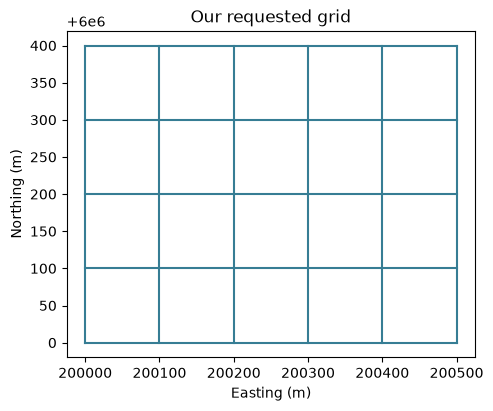

Region observation: 480


In [2]:
area = RectangularGeometry(200000, 200500, 6000000, 6000400, 5, 4)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for x in range(200000, 200501, 100):
    ax.plot([x, x], [6000000, 6000400], color="#367d94")
for y in range(6000000, 6000401, 100):
    ax.plot([200000, 200500], [y, y], color="#367d94")
ax.set(title="Our requested grid", xlabel="Easting (m)", ylabel="Northing (m)", aspect="equal")
plt.show()
region = context.observe(ObservationRequest("earth:Region", geometry=area)).result(120)
focused = context.within(region)
print("Region observation:", region.id)

## Compute a field and read the result
The TEST aspect model returns different values across the grid, including a
legitimate zero and one missing cell. The plot below uses actual cell reads.

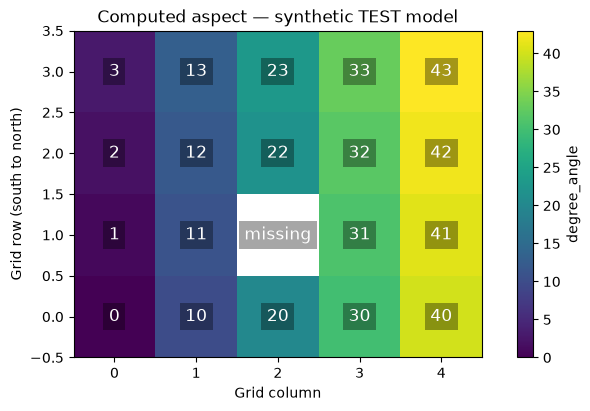

Job: 59 | observation: 484 | unit: degree_angle


In [3]:
reset_field()  # TEST-only: reset this known-answer model before its next run.
job = focused.observe("geography:Aspect in degree_angle")
aspect = job.result(timeout=120)
native = plot_grid(aspect, title="Computed aspect — synthetic TEST model")
assert native == tuple(None if (x, y) == (2, 1) else x * 10 + y
                       for y in range(4) for x in range(5))
print("Job:", job.id, "| observation:", aspect.id, "| unit:", aspect.units)

## Read in another unit
Request conversion from the service rather than relabeling the numbers locally.

In [4]:
from klab_client.dto import storage_semantics

elevation = focused.observe("geography:Elevation in m").result(120)
metres = elevation.fetch_data(range(20), curve="D2_YX")
millimetres = elevation.fetch_data(range(20), curve="D2_YX",
    semantics=storage_semantics(client.reasoner.resolve_observable("geography:Elevation in mm")))
display(pd.DataFrame({"cell": range(5), "metres": metres.values[:5],
                      "millimetres": millimetres.values[:5]}))
assert all(m == 123.25 and mm == 123250 for m, mm in zip(metres.values, millimetres.values))

,cell,metres,millimetres
0,0,123.25,123250
1,1,123.25,123250
2,2,123.25,123250
3,3,123.25,123250
4,4,123.25,123250


## Choose a scenario, namespace or project
These choices select different supported models. Use a separate context for the
scenario comparison: requesting an already-observed quantity in the original
context can return the existing observation rather than recomputing it.

,selection,value,unit
0,Base elevation,123.25,m
1,Scenario elevation,234.50,m
2,Namespace depth,66.50,m
3,Project slope,7.50,degree_angle


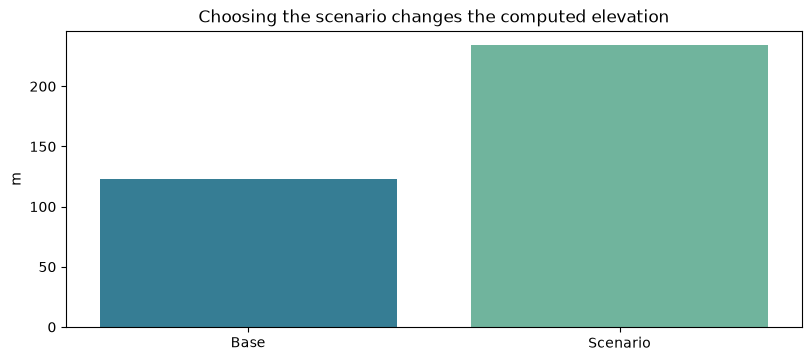

In [5]:
scenario_context = session.create_context(name="Scenario comparison")
scenario_region = scenario_context.observe(ObservationRequest("earth:Region", geometry=area)).result(120)
scenario = scenario_context.within(scenario_region).observe("geography:Elevation in m",
    options=ObservationOptions(scenarios=["python.scenario"])).result(120)
depth = focused.observe("geography:BathymetricDepth in m",
    options=ObservationOptions(namespace="python.lexical")).result(120)
slope = focused.observe("geography:Slope in degree_angle",
    options=ObservationOptions(project="python.fixture")).result(120)
choices = pd.DataFrame([
    {"selection": "Base elevation", "value": float(metres.values[0]), "unit": "m"},
    {"selection": "Scenario elevation", "value": float(scenario.fetch_data([0]).values[0]), "unit": "m"},
    {"selection": "Namespace depth", "value": float(depth.fetch_data([0]).values[0]), "unit": "m"},
    {"selection": "Project slope", "value": float(slope.fetch_data([0]).values[0]), "unit": "degree_angle"},
])
display(choices)
assert choices.value.tolist() == [123.25, 234.5, 66.5, 7.5], choices.to_dict("records")
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.bar(["Base", "Scenario"], choices.value.iloc[:2], color=["#367d94", "#70b49d"])
ax.set(title="Choosing the scenario changes the computed elevation", ylabel="m")
plt.show()

## Select an observer and set a context grid
An observer must be an actual supported agent, not an arbitrary measured quality.

In [6]:
observer_id = context.configuration["observer"]["id"]
observed = focused.observe("geography:Elevation in m",
    options=ObservationOptions(observer=observer_id))
observed.result(120)
assert observed.scope.get_context_id().endswith(f"#{observer_id}")
lattice = session.create_context(options=ContextOptions(name="Aligned study grid",
    grid=GridOptions(500000, 0, 100, projection="EPSG:32631")))
display(lattice.configuration["gridAlignment"])
assert lattice.configuration["gridAlignment"]["projection"] == "EPSG:32631"
assert session.release()
connection.close()
print("The example's remote session was explicitly released.")

{'@CLASS': 'org.integratedmodelling.klab.api.digitaltwin.GridAlignment',
 'version': 1,
 'definitionUrn': 'urn:klab:grid:inline:65bae5da6a4a4fd4813fbc56cad472501f0be3e2912a46d45790483a17795a5d',
 'fingerprint': '2c958c9f9393384d0a6218dbc87141f239b0e4e1afab3d9ccdcc5451a5968b6f',
 'projection': 'EPSG:32631',
 'anchorX': 500000.0,
 'anchorY': 0.0,
 'stepX': 100.0,
 'stepY': 100.0,
 'strict': True,
 'snap': False,
 'levels': [9.5367431640625e-07,
  1.9073486328125e-06,
  3.814697265625e-06,
  7.62939453125e-06,
  1.52587890625e-05,
  3.0517578125e-05,
  6.103515625e-05,
  0.0001220703125,
  0.000244140625,
  0.00048828125,
  0.0009765625,
  0.001953125,
  0.00390625,
  0.0078125,
  0.015625,
  0.03125,
  0.0625,
  0.125,
  0.25,
  0.5,
  1.0,
  2.0,
  4.0,
  8.0,
  16.0,
  32.0,
  64.0,
  128.0,
  256.0,
  512.0,
  1024.0,
  2048.0,
  4096.0,
  8192.0,
  16384.0,
  32768.0,
  65536.0,
  131072.0,
  262144.0,
  524288.0,
  1048576.0],
 'warnings': [],
 'codeDefinition': 'define grid grid_65

The example's remote session was explicitly released.
